In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from matplotlib import pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score
from sklearn.multioutput import MultiOutputRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor
from pyspark.sql import SparkSession

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
pd.set_option('display.max_columns', None)

In [2]:
spark = SparkSession.builder \
    .appName("Velib_Models_Training") \
    .getOrCreate()

OUTPUT_PATH = "hdfs://localhost:9000/user/hadoop/data/data_with_meteo_final"
spark_df = spark.read.parquet(OUTPUT_PATH)

spark_df.printSchema()
spark_df.show(5)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
25/12/28 17:08:03 WARN Utils: Your hostname, yassi, resolves to a loopback address: 127.0.1.1; using 10.188.31.196 instead (on interface wlp59s0)
25/12/28 17:08:03 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/12/28 17:08:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


root
 |-- stationcode: string (nullable = true)
 |-- name: string (nullable = true)
 |-- is_installed: string (nullable = true)
 |-- capacity: long (nullable = true)
 |-- numdocksavailable: long (nullable = true)
 |-- numbikesavailable: long (nullable = true)
 |-- mechanical: long (nullable = true)
 |-- ebike: long (nullable = true)
 |-- is_renting: string (nullable = true)
 |-- is_returning: string (nullable = true)
 |-- duedate: timestamp (nullable = true)
 |-- coordonnees_geo: struct (nullable = true)
 |    |-- lat: double (nullable = true)
 |    |-- lon: double (nullable = true)
 |-- nom_arrondissement_communes: string (nullable = true)
 |-- code_insee_commune: string (nullable = true)
 |-- temperature_2m: double (nullable = true)
 |-- precipitation: double (nullable = true)
 |-- rain: double (nullable = true)
 |-- snowfall: double (nullable = true)
 |-- relative_humidity_2m: double (nullable = true)
 |-- is_holiday: integer (nullable = true)
 |-- hour: integer (nullable = true)
 |

25/12/28 17:08:21 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+-----------+--------------------+------------+--------+-----------------+-----------------+----------+-----+----------+------------+-------------------+--------------------+---------------------------+------------------+--------------+-------------+----+--------+--------------------+----------+----+-----+---------+----------+--------+--------------------+-------------------+------------------+-------------------+-------------------+----------+
|stationcode|                name|is_installed|capacity|numdocksavailable|numbikesavailable|mechanical|ebike|is_renting|is_returning|            duedate|     coordonnees_geo|nom_arrondissement_communes|code_insee_commune|temperature_2m|precipitation|rain|snowfall|relative_humidity_2m|is_holiday|hour|month|dayofweek|is_weekend|hour_sin|            hour_cos|            dow_sin|           dow_cos|        bikes_ratio|        docks_ratio|is_raining|
+-----------+--------------------+------------+--------+-----------------+-----------------+----------

In [3]:
df = df = spark_df.toPandas()
df.head()

,stationcode,name,is_installed,capacity,numdocksavailable,numbikesavailable,mechanical,ebike,is_renting,is_returning,duedate,coordonnees_geo,nom_arrondissement_communes,code_insee_commune,temperature_2m,precipitation,rain,snowfall,relative_humidity_2m,is_holiday,hour,month,dayofweek,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos,bikes_ratio,docks_ratio,is_raining
0,16107,Benjamin Godard - Victor Hugo,OUI,35.0,30,4,2,2,OUI,OUI,2025-12-17 06:26:32,"(48.865983, 2.275725)",Paris,75056,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.0,6.123234e-17,0.433884,-0.900969,0.114286,0.857143,0
1,40001,Hôpital Mondor,OUI,28.0,12,17,2,15,OUI,OUI,2025-12-17 06:33:29,"(48.798922410229, 2.4537451531298)",Créteil,94028,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.0,6.123234e-17,0.433884,-0.900969,0.607143,0.428571,0
2,32304,Charcot - Benfleet,OUI,28.0,22,4,2,2,OUI,OUI,2025-12-17 06:28:10,"(48.878370277021, 2.440523876268)",Romainville,93063,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.0,6.123234e-17,0.433884,-0.900969,0.142857,0.785714,0
3,11104,Charonne - Robert et Sonia Delaunay,OUI,20.0,12,8,1,7,OUI,OUI,2025-12-17 06:32:00,"(48.855907555969, 2.3925706744194)",Paris,75056,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.0,6.123234e-17,0.433884,-0.900969,0.400000,0.600000,0
4,8026,Messine - Place Du Pérou,OUI,12.0,7,4,4,0,OUI,OUI,2025-12-17 06:33:20,"(48.875448033960744, 2.315508019010038)",Paris,75056,8.5,0.0,0.0,0.0,99.325005,0,6,12,3,0,1.0,6.123234e-17,0.433884,-0.900969,0.333333,0.583333,0


In [4]:
targets = ['numbikesavailable', 'numdocksavailable']

# On retire les colonnes brutes (dates, IDs, targets) et celles encodées autrement
drop_cols = ['duedate', 'numbikesavailable', 'numdocksavailable', 'nom_arrondissement_communes','is_returning', 'coordonnees_geo', 'is_renting', 'is_installed', 'code_insee_commune']

# Features numériques et catégorielles
categorical_features = ['is_weekend']  # + 'nom_arrondissement' si pertinent
numeric_features = [col for col in df.columns
                    if col not in drop_cols + targets + categorical_features]

X = df.drop(columns=drop_cols + targets)
# Note : on garde X aligné, on sélectionnera les colonnes via ColumnTransformer
y = df[targets]

# --- SPLIT TEMPOREL ---
train_size = int(len(df) * 0.8)
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

print(f"\nTrain set : {X_train.shape}")
print(f"Test set  : {X_test.shape}")


Train set : (143336, 22)
Test set  : (35834, 22)


In [5]:
categorical_features = X.select_dtypes(include=["object", "category"]).columns
categorical_features

Index(['stationcode', 'name'], dtype='object')

In [6]:
numeric_features = X.select_dtypes(exclude=['object']).columns


def create_preprocessor(num_features, cat_features):
    numeric_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ('scaler', StandardScaler())
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]
    )

    pipeline = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, num_features),
            ("cat", categorical_transformer, cat_features),
        ]
    )

    return pipeline

In [6]:
preprocessor = create_preprocessor(numeric_features, categorical_features)

catboost = CatBoostRegressor(loss_function='MultiRMSE', verbose=None)

xgb = MultiOutputRegressor(XGBRegressor(verbose=None))

lgbm = MultiOutputRegressor(LGBMRegressor(verbose=None))

random_forest = RandomForestRegressor(verbose=0)

models = {
    "CatBoost": catboost,
    "XGBoost": xgb,
    "LightGBM": lgbm,
    "RandomForest": random_forest
}

In [23]:
for key, model in models.items():
    start = time.time()
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])

    scores = cross_val_score(pipeline, X_train, y_train, cv=3, scoring='r2', n_jobs=-1)

    elapsed = time.time() - start
    print(f"{key}: R2 Moyen = {scores.mean():.4f} (+/- {scores.std():.4f}) - Temps: {elapsed:.1f}s")

0:	learn: 16.0755224	total: 70.2ms	remaining: 1m 10s
1:	learn: 15.6394773	total: 101ms	remaining: 50.6s
2:	learn: 15.2164535	total: 126ms	remaining: 42s
3:	learn: 14.8058456	total: 143ms	remaining: 35.7s
4:	learn: 14.4055215	total: 171ms	remaining: 33.9s
5:	learn: 14.0231240	total: 206ms	remaining: 34.1s
6:	learn: 13.6466795	total: 228ms	remaining: 32.4s
7:	learn: 13.2864950	total: 256ms	remaining: 31.7s
8:	learn: 12.9299991	total: 272ms	remaining: 29.9s
9:	learn: 12.5905272	total: 304ms	remaining: 30.1s
10:	learn: 12.2570049	total: 328ms	remaining: 29.5s
11:	learn: 11.9318394	total: 353ms	remaining: 29.1s
12:	learn: 11.6156305	total: 377ms	remaining: 28.6s
13:	learn: 11.3100825	total: 397ms	remaining: 28s
14:	learn: 11.0122491	total: 422ms	remaining: 27.7s
15:	learn: 10.7297187	total: 439ms	remaining: 27s
0:	learn: 16.5017280	total: 110ms	remaining: 1m 50s
16:	learn: 10.4485031	total: 459ms	remaining: 26.5s
17:	learn: 10.1738313	total: 478ms	remaining: 26.1s
1:	learn: 16.0575337	total

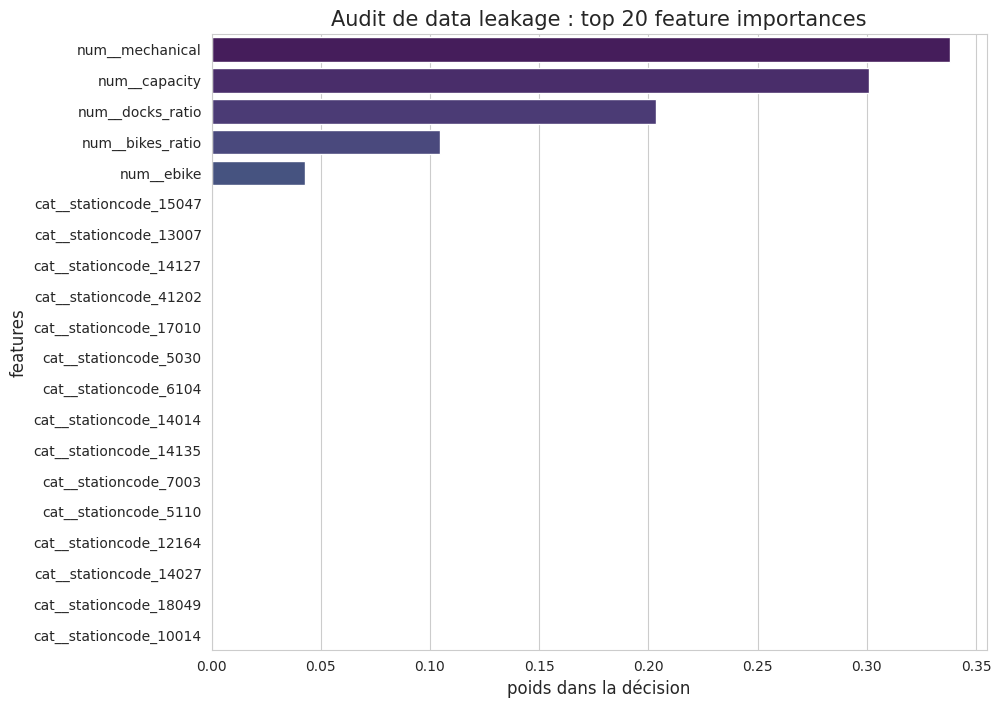


--- TOP 10 VARIABLES SUSPECTES ---
                     Feature  Importance
1            num__mechanical    0.337858
0              num__capacity    0.300844
18          num__docks_ratio    0.203244
17          num__bikes_ratio    0.104392
2                 num__ebike    0.042660
389   cat__stationcode_15047    0.000204
228   cat__stationcode_13007    0.000201
336   cat__stationcode_14127    0.000172
1185  cat__stationcode_41202    0.000157
505   cat__stationcode_17010    0.000151


In [7]:
# Choix final : XGBoost
# Performance : C'est le meilleur score ($R^2 = 0.9982$), même si la différence est minime.
# Vitesse : C'est le plus rapide (6.3s).
# Efficacité : Comparé au RandomForest (684s), XGBoost est 100 fois plus rapide pour un résultat légèrement meilleur.


xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', xgb)
])

xgb_pipeline.fit(X_train, y_train)

# Extraction des noms des features
try:
    feature_names = xgb_pipeline.named_steps['preprocessor'].get_feature_names_out()
except AttributeError:
    feature_names = X_train.columns

# Extraction des importances
multi_output_model = xgb_pipeline.named_steps['model']
importances_per_target = [est.feature_importances_ for est in multi_output_model.estimators_]

# On fait la moyenne des importances sur toutes les cibles
mean_importances = np.mean(importances_per_target, axis=0)

# Création du DataFrame pour l'affichage
df_imp = pd.DataFrame({
    'Feature': feature_names,
    'Importance': mean_importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
# On affiche le Top 20 pour la lisibilité
sns.barplot(x='Importance', y='Feature', data=df_imp.head(20), palette='viridis')
plt.title('Audit de data leakage : top 20 feature importances', fontsize=15)
plt.xlabel('poids dans la décision', fontsize=12)
plt.ylabel('features', fontsize=12)
plt.show()

# Affichage textuel du Top 10 pour vérification immédiate
print("\n--- TOP 10 VARIABLES SUSPECTES ---")
print(df_imp.head(10))